<a href="https://colab.research.google.com/github/huyhoangk5/Nhom03_BTL_BDA/blob/main/Nhom03_BTL_BDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Nhóm 1


In [ ]:
!pip install pandas numpy matplotlib seaborn scipy

In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/PTDuLieuLon/diabetes_dataset00.csv')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Tổng quan dữ liệu
print(df.shape)
print("Số ô thiếu: ", df.isna().sum().sum())
print ("Số ô dòng trùng: ", df.duplicated().sum())
df.info()
df.head()

(70000, 34)
Số ô thiếu:  0
Số ô dòng trùng:  0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 34 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Target                         70000 non-null  object
 1   Genetic Markers                70000 non-null  object
 2   Autoantibodies                 70000 non-null  object
 3   Family History                 70000 non-null  object
 4   Environmental Factors          70000 non-null  object
 5   Insulin Levels                 70000 non-null  int64 
 6   Age                            70000 non-null  int64 
 7   BMI                            70000 non-null  int64 
 8   Physical Activity              70000 non-null  object
 9   Dietary Habits                 70000 non-null  object
 10  Blood Pressure                 70000 non-null  int64 
 11  Cholesterol Levels             70000 non-null  int64 
 12  Waist Circumf

,Target,Genetic Markers,Autoantibodies,Family History,Environmental Factors,Insulin Levels,Age,BMI,Physical Activity,Dietary Habits,...,Pulmonary Function,Cystic Fibrosis Diagnosis,Steroid Use History,Genetic Testing,Neurological Assessments,Liver Function Tests,Digestive Enzyme Levels,Urine Test,Birth Weight,Early Onset Symptoms
0,Steroid-Induced Diabetes,Positive,Negative,No,Present,40,44,38,High,Healthy,...,76,No,No,Positive,3,Normal,56,Ketones Present,2629,No
1,Neonatal Diabetes Mellitus (NDM),Positive,Negative,No,Present,13,1,17,High,Healthy,...,60,Yes,No,Negative,1,Normal,28,Glucose Present,1881,Yes
2,Prediabetic,Positive,Positive,Yes,Present,27,36,24,High,Unhealthy,...,80,Yes,No,Negative,1,Abnormal,55,Ketones Present,3622,Yes
3,Type 1 Diabetes,Negative,Positive,No,Present,8,7,16,Low,Unhealthy,...,89,Yes,No,Positive,2,Abnormal,60,Ketones Present,3542,No
4,Wolfram Syndrome,Negative,Negative,Yes,Present,17,10,17,High,Healthy,...,41,No,No,Positive,1,Normal,24,Protein Present,1770,No


In [ ]:
#Phân loại các cột (Cột số và cột chữ)
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.drop('Target').to_list()
print(len(num_cols),"cột số: ", num_cols)
print(len(cat_cols),"cột chữ: ", cat_cols)
print(df[cat_cols].nunique())

13 cột số:  ['Insulin Levels', 'Age', 'BMI', 'Blood Pressure', 'Cholesterol Levels', 'Waist Circumference', 'Blood Glucose Levels', 'Weight Gain During Pregnancy', 'Pancreatic Health', 'Pulmonary Function', 'Neurological Assessments', 'Digestive Enzyme Levels', 'Birth Weight']
20 cột chữ:  ['Genetic Markers', 'Autoantibodies', 'Family History', 'Environmental Factors', 'Physical Activity', 'Dietary Habits', 'Ethnicity', 'Socioeconomic Factors', 'Smoking Status', 'Alcohol Consumption', 'Glucose Tolerance Test', 'History of PCOS', 'Previous Gestational Diabetes', 'Pregnancy History', 'Cystic Fibrosis Diagnosis', 'Steroid Use History', 'Genetic Testing', 'Liver Function Tests', 'Urine Test', 'Early Onset Symptoms']
Genetic Markers                  2
Autoantibodies                   2
Family History                   2
Environmental Factors            2
Physical Activity                3
Dietary Habits                   2
Ethnicity                        2
Socioeconomic Factors            

In [ ]:
#Thống kê mô tả  của các loại chỉ số
stats = df[num_cols].describe().T
stats['skew'] = df[num_cols].skew()
stats = stats.round(2)
stats

,count,mean,std,min,25%,50%,75%,max,skew
Insulin Levels,70000.0,21.61,10.79,5.0,13.0,19.0,28.00,49.0,0.71
Age,70000.0,32.02,21.04,0.0,14.0,31.0,49.00,79.0,0.23
BMI,70000.0,24.78,6.01,12.0,20.0,25.0,29.00,39.0,0.09
Blood Pressure,70000.0,111.34,19.94,60.0,99.0,113.0,125.00,149.0,-0.38
Cholesterol Levels,70000.0,194.87,44.53,100.0,163.0,191.0,225.00,299.0,0.26
Waist Circumference,70000.0,35.05,6.80,20.0,30.0,34.0,39.00,54.0,0.37
Blood Glucose Levels,70000.0,160.70,48.17,80.0,121.0,152.0,194.00,299.0,0.62
Weight Gain During Pregnancy,70000.0,15.50,9.63,0.0,7.0,16.0,22.00,39.0,0.16
Pancreatic Health,70000.0,47.56,19.98,10.0,32.0,46.0,64.00,99.0,0.18
Pulmonary Function,70000.0,70.26,11.97,30.0,63.0,72.0,79.00,89.0,-0.81


In [ ]:
#Phát hiện ngoại lai theo quy tắc IQR
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
low = Q1- 1.5*IQR
high = Q3 + 1.5*IQR
n_outliers = ((df[num_cols]<low) | (df[num_cols]>high)).sum()
n_outliers

,0
Insulin Levels,0
Age,0
BMI,0
Blood Pressure,0
Cholesterol Levels,0
Waist Circumference,522
Blood Glucose Levels,0
Weight Gain During Pregnancy,0
Pancreatic Health,0
Pulmonary Function,1206


In [ ]:
#Lưu lại vào dile
stats.to_csv('/content/drive/MyDrive/PTDuLieuLon/bang_thong_ke_mo_ta.csv')

In [ ]:
#Đếm số mẫu và tỷ lệ từng lớp
counts = df['Target'].value_counts()
pct = (counts/len(df)*100).round(2)
bang_lop = pd.DataFrame({'Số mẫu':counts,' Tỷ lệ(%)': pct})
print(bang_lop)
ti_le = counts.max()/counts.min()
print(f'Imbalance ratio (lớn nhất/nhỏ nhất) = {ti_le:.3f}')
print(f'Số mẫu kỳ vọng nêu mỗi lớp cân bằng là: {len(df)/13:.0f}')

                                            Số mẫu   Tỷ lệ(%)
Target                                                       
MODY                                          5553       7.93
Secondary Diabetes                            5479       7.83
Cystic Fibrosis-Related Diabetes (CFRD)       5464       7.81
Type 1 Diabetes                               5446       7.78
Neonatal Diabetes Mellitus (NDM)              5408       7.73
Wolcott-Rallison Syndrome                     5400       7.71
Type 2 Diabetes                               5397       7.71
Prediabetic                                   5376       7.68
Gestational Diabetes                          5344       7.63
Type 3c Diabetes (Pancreatogenic Diabetes)    5320       7.60
Wolfram Syndrome                              5315       7.59
Steroid-Induced Diabetes                      5275       7.54
LADA                                          5223       7.46
Imbalance ratio (lớn nhất/nhỏ nhất) = 1.063
Số mẫu kỳ vọng nêu mỗi lớp

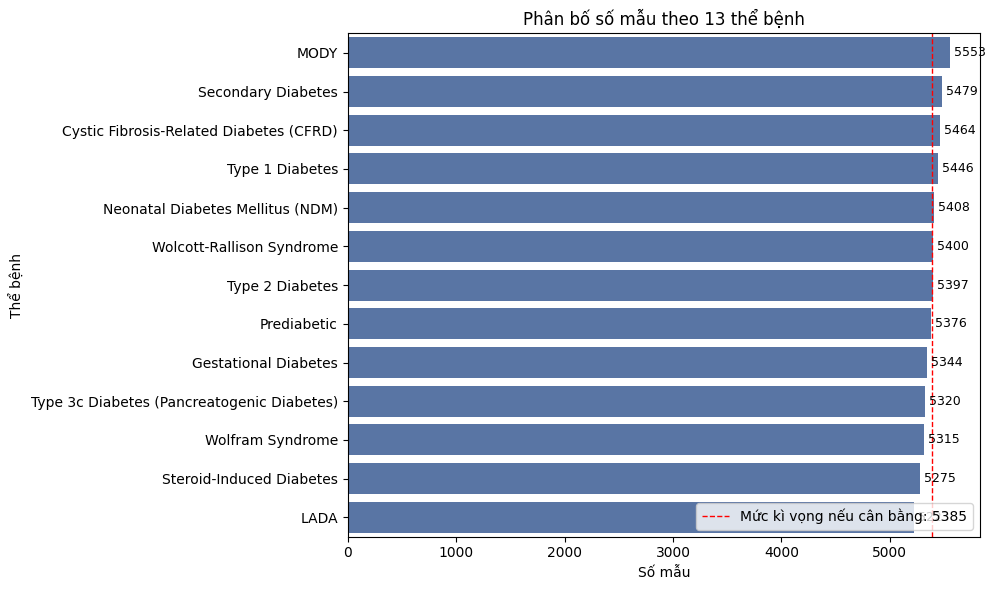

In [ ]:
#Vẽ biểu đồ cột
fig,ax = plt.subplots(figsize=(10,6))
sns.countplot(data=df,y='Target', order=counts.index,color='#4c72b0',ax=ax)
for c in ax.containers:
  ax.bar_label(c,fmt='%d', padding=3,fontsize=9)
  ax.axvline(len(df)/13,color='red',linestyle='--', linewidth=1,
             label=f'Mức kì vọng nếu cân bằng: {len(df)/13:.0f}')
ax.set_title('Phân bố số mẫu theo 13 thể bệnh')
ax.set_xlabel('Số mẫu'); ax.set_ylabel('Thể bệnh')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('eda_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
#Kiểm định thống kê
from scipy.stats import chisquare

chi2, p = chisquare(counts.values)     # mặc định: so với phân phối đều
print(f"chi2 = {chi2:.2f}, p = {p:.4f}")

# Entropy chuẩn hóa: 1.0 là phân phối đều hoàn toàn
prob = counts / counts.sum()
entropy = -(prob * np.log(prob)).sum() / np.log(len(counts))
print(f"Entropy chuẩn hóa = {entropy:.4f}")

chi2 = 18.04, p = 0.1144
Entropy chuẩn hóa = 0.9999


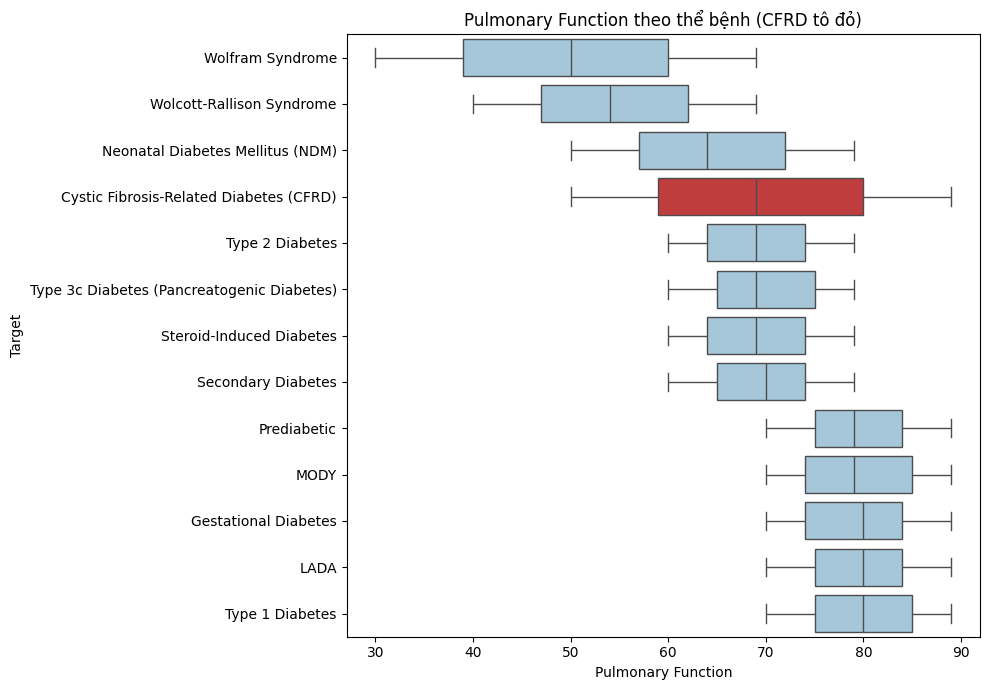

In [ ]:
#Boxplot Pulmonary Function theo thể bệnh
order = df.groupby('Target')['Pulmonary Function'].median().sort_values().index
palette = {t: ('#d62728' if t.startswith('Cystic') else '#9ecae1') for t in order}

plt.figure(figsize=(10, 7))
sns.boxplot(data=df, y='Target', x='Pulmonary Function', order=order,
            hue='Target', palette=palette, legend=False)
plt.title('Pulmonary Function theo thể bệnh (CFRD tô đỏ)')
plt.tight_layout()
plt.savefig('eda_pulmonary.png', dpi=300, bbox_inches='tight')
plt.show()

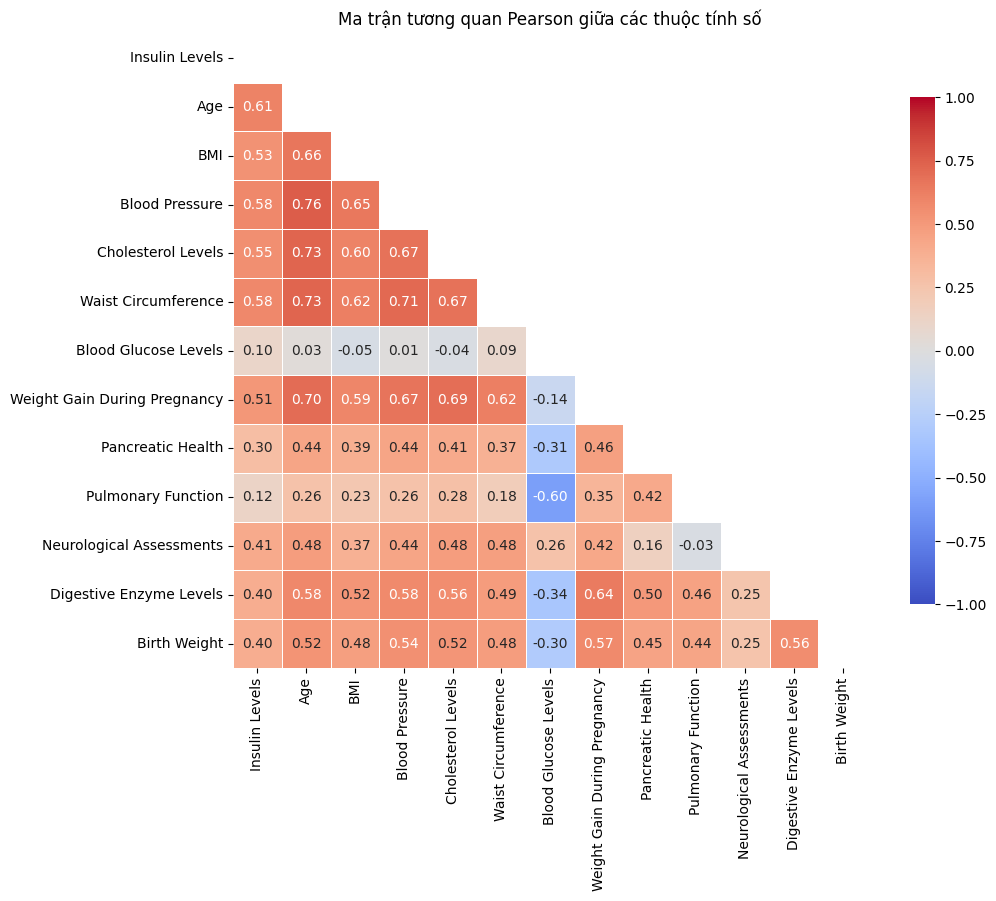

Blood Pressure                Age                   0.763
Waist Circumference           Age                   0.734
Cholesterol Levels            Age                   0.730
Waist Circumference           Blood Pressure        0.713
Weight Gain During Pregnancy  Age                   0.698
                              Cholesterol Levels    0.692
Cholesterol Levels            Blood Pressure        0.675
Waist Circumference           Cholesterol Levels    0.673
dtype: float64


In [ ]:
corr = df[num_cols].corr()                       # mặc định: Pearson
mask = np.triu(np.ones_like(corr, dtype=bool))   # ẩn nửa trên (đối xứng, lặp lại)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Ma trận tương quan Pearson giữa các thuộc tính số')
plt.tight_layout()
plt.savefig('eda_corr_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Liệt kê các cặp tương quan mạnh nhất
pairs = corr.where(~mask).stack().sort_values(key=abs, ascending=False)
print(pairs.head(8).round(3))

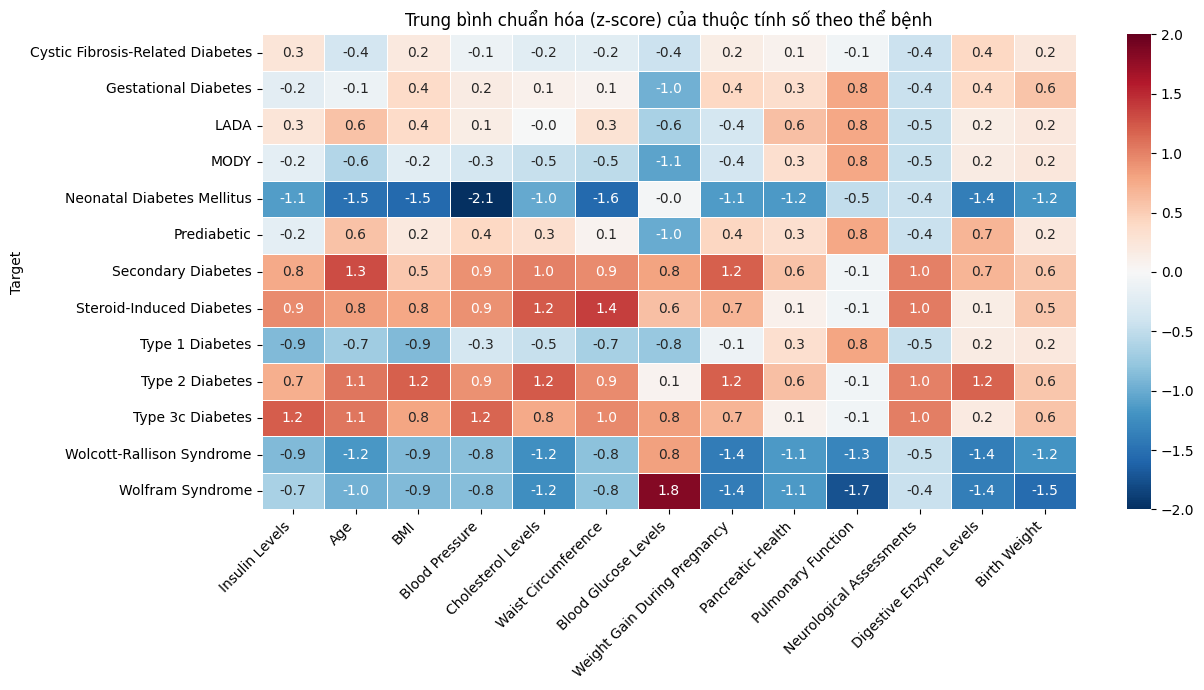

In [ ]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()   # chuẩn hóa z-score
z['Target'] = df['Target']
profile = z.groupby('Target').mean()
profile.index = profile.index.str.replace(r' \(.*\)', '', regex=True)  # rút gọn tên

plt.figure(figsize=(13, 7))
sns.heatmap(profile, annot=True, fmt='.1f', cmap='RdBu_r', center=0,
            vmin=-2, vmax=2, linewidths=0.5)
plt.title('Trung bình chuẩn hóa (z-score) của thuộc tính số theo thể bệnh')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('eda_profile_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df['Target'])

for i, ten in enumerate(le.classes_):
    print(i, ten)

0 Cystic Fibrosis-Related Diabetes (CFRD)
1 Gestational Diabetes
2 LADA
3 MODY
4 Neonatal Diabetes Mellitus (NDM)
5 Prediabetic
6 Secondary Diabetes
7 Steroid-Induced Diabetes
8 Type 1 Diabetes
9 Type 2 Diabetes
10 Type 3c Diabetes (Pancreatogenic Diabetes)
11 Wolcott-Rallison Syndrome
12 Wolfram Syndrome


In [ ]:
BINARY_MAP = {   # (giá trị mã hóa 0, giá trị mã hóa 1)
    'Genetic Markers': ('Negative', 'Positive'), 'Autoantibodies': ('Negative', 'Positive'),
    'Family History': ('No', 'Yes'), 'Environmental Factors': ('Absent', 'Present'),
    'Dietary Habits': ('Healthy', 'Unhealthy'), 'Ethnicity': ('Low Risk', 'High Risk'),
    'Smoking Status': ('Non-Smoker', 'Smoker'), 'Glucose Tolerance Test': ('Normal', 'Abnormal'),
    'History of PCOS': ('No', 'Yes'), 'Previous Gestational Diabetes': ('No', 'Yes'),
    'Pregnancy History': ('Normal', 'Complications'), 'Cystic Fibrosis Diagnosis': ('No', 'Yes'),
    'Steroid Use History': ('No', 'Yes'), 'Genetic Testing': ('Negative', 'Positive'),
    'Liver Function Tests': ('Normal', 'Abnormal'), 'Early Onset Symptoms': ('No', 'Yes'),
}
ORDINAL_MAP = {
    'Physical Activity':     {'Low': 0, 'Moderate': 1, 'High': 2},
    'Socioeconomic Factors': {'Low': 0, 'Medium': 1,   'High': 2},
    'Alcohol Consumption':   {'Low': 0, 'Moderate': 1, 'High': 2},
}
URINE_CATS = ['Glucose Present', 'Ketones Present', 'Protein Present']

def encode_features(data):
    out = data.copy()
    for col, (neg, pos) in BINARY_MAP.items():
        out[col] = out[col].map({neg: 0, pos: 1})
        assert out[col].notna().all(), f'Giá trị lạ ở cột {col}'
        out[col] = out[col].astype(int)
    for col, mp in ORDINAL_MAP.items():
        out[col] = out[col].map(mp)
        assert out[col].notna().all(), f'Giá trị lạ ở cột {col}'
        out[col] = out[col].astype(int)
    assert out['Urine Test'].isin(['Normal'] + URINE_CATS).all(), 'Giá trị lạ ở Urine Test'
    for cat in URINE_CATS:
        out[f'Urine Test_{cat}'] = (out['Urine Test'] == cat).astype(int)
    return out.drop(columns='Urine Test')

In [ ]:
print(X_enc.shape)                              # kỳ vọng (70000, 35)
print(X_enc.select_dtypes('object').shape[1])   # kỳ vọng 0: không còn cột chữ
print(X_enc.dtypes.value_counts())              # toàn bộ phải là số
print(X_enc[['Autoantibodies', 'Dietary Habits']].mean())   # kỳ vọng ≈ 0,5
X_enc.head()

(70000, 35)
0
int64    35
Name: count, dtype: int64
Autoantibodies    0.499171
Dietary Habits    0.499714
dtype: float64


,Genetic Markers,Autoantibodies,Family History,Environmental Factors,Insulin Levels,Age,BMI,Physical Activity,Dietary Habits,Blood Pressure,...,Steroid Use History,Genetic Testing,Neurological Assessments,Liver Function Tests,Digestive Enzyme Levels,Birth Weight,Early Onset Symptoms,Urine Test_Glucose Present,Urine Test_Ketones Present,Urine Test_Protein Present
0,1,0,0,1,40,44,38,2,0,124,...,0,1,3,0,56,2629,0,0,1,0
1,1,0,0,1,13,1,17,2,0,73,...,0,0,1,0,28,1881,1,1,0,0
2,1,1,1,1,27,36,24,2,1,121,...,0,0,1,1,55,3622,1,0,1,0
3,0,1,0,1,8,7,16,0,1,100,...,0,1,2,1,60,3542,0,0,1,0
4,0,0,1,1,17,10,17,2,0,103,...,0,1,1,0,24,1770,0,0,0,1


In [ ]:
import joblib
joblib.dump(le, '/content/drive/MyDrive/label_encoder.pkl')

['/content/drive/MyDrive/label_encoder.pkl']

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='Target')          # dữ liệu thô, chưa mã hóa
y = le.transform(df['Target'])         # nhãn đã mã hóa ở bước E1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)     # (56000, 33) (14000, 33)

(56000, 33) (14000, 33)


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler

class DiabetesPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, num_cols):
        self.num_cols = num_cols

    def fit(self, X, y=None):
        X_enc = encode_features(X)
        self.feature_names_ = list(X_enc.columns)               # nhớ thứ tự cột
        self.scaler_ = StandardScaler().fit(X_enc[self.num_cols])  # học mean, std
        return self

    def transform(self, X):
        X_enc = encode_features(X)[self.feature_names_].copy()   # đúng thứ tự cột
        X_enc[self.num_cols] = self.scaler_.transform(X_enc[self.num_cols])
        return X_enc

In [ ]:
pre = DiabetesPreprocessor(num_cols)

X_train_p = pre.fit_transform(X_train)    # HỌC trên Train rồi biến đổi Train
X_test_p  = pre.transform(X_test)         # CHỈ biến đổi Test, tuyệt đối không fit

print(X_train_p.shape, X_test_p.shape)    # (56000, 35) (14000, 35)

(56000, 35) (14000, 35)


In [ ]:
print(X_train_p[num_cols].mean().abs().max())   # ≈ 0
print(X_train_p[num_cols].std().round(3).unique())   # ≈ 1
print(X_test_p[num_cols].mean().abs().max())    # gần 0 nhưng KHÔNG đúng bằng 0
print(X_test_p[num_cols].std().min(), X_test_p[num_cols].std().max())
print(X_train_p.isna().sum().sum())             # 0

3.113699774205868e-16
[1.]
0.011931017292816348
0.993481301595588 1.008089760302077
0
